In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from statsmodels.stats.power import TTestPower

# QuickCart — Case 1: One Population Mean
 
**Task:** Plan the number of post-upgrade deliveries needed to determine whether average delivery time differs from 30 minutes.

## 1. Business problem and assumptions

QuickCart promises an average delivery time of **30 minutes**. After a routing-system upgrade, the Operations Manager expects the mean may be **27 minutes** and wants to test whether it **has changed in either direction**. Historical records suggest a delivery-time standard deviation of approximately **8 minutes**.

| Planning quantity | Value | Meaning |
|---|---:|---|
| Reference mean, $\mu_0$ | 30 minutes | Fixed historical benchmark |
| Anticipated mean, $\mu_1$ | 27 minutes | Alternative value used to design the study |
| Absolute MDE, $\delta$ | $|27-30|=3$ minutes | Difference the study aims to detect with target power |
| Planning SD | 8 minutes | Historical **estimate**, not known population SD |
| Significance level, $\alpha$ | 0.05 | Two-sided Type I error rate |
| Desired power, $1-\beta$ | 0.90 | Power at the specified alternative |

**Design assumptions:** Delivery-time observations are independent; the post-upgrade distribution is approximately normal (as specified in the exercise); and the 30-minute benchmark is treated as fixed rather than estimated from a separate historical sample. In actual logistics data, deliveries can be correlated within drivers, shifts, or regions; if so, this simple model may underestimate the required sample size.

**Important:** This is a *one-sample* study: we will sample deliveries **after the upgrade** and compare their mean with 30 minutes. No separate control group is part of the stated design.

## 2. Statistical test and hypotheses

The outcome (delivery time) is continuous. We compare **one new sample mean** to a fixed reference value. Since the population SD is not known and will be estimated from the new sample, a **two-sided one-sample t-test** is appropriate under the stated assumptions.

$$H_0: \mu = 30 \text{ minutes}$$
$$H_a: \mu \ne 30 \text{ minutes}$$

A two-sided alternative is appropriate because the manager asked whether the mean *changed*, not only whether it fell. The anticipated 27-minute mean determines the **planning effect size**, but does **not** change the two-sided hypotheses.

A historical estimate of SD is sufficient for power *planning*. At analysis time, the t-test uses the standard deviation computed from the newly collected observations.

The new routing system cannot be established as the *cause* of any change from this one-sample before/after-benchmark comparison alone.

In [3]:
# QuickCart planning inputs
reference_mean = 30.0       # minutes
anticipated_mean = 27.0     # minutes
planning_sd = 8.0          # historical estimated SD (minutes)
alpha = 0.05
target_power = 0.90
alternative = "two-sided"

mde = abs(anticipated_mean - reference_mean)
standardized_effect = mde / planning_sd
print(f"Absolute MDE: {mde:.1f} minutes")
print(f"Standardized effect size |d|: {standardized_effect:.3f}")

Absolute MDE: 3.0 minutes
Standardized effect size |d|: 0.375


## 3. Manual Z-based sample-size approximation

For a two-sided **one-sample mean** normal approximation:

$$n \approx \frac{\left(z_{1-\alpha/2}+z_{1-\beta}\right)^2 \sigma_{\mathrm{planning}}^2}{\delta^2}$$

This is **not** the exact one-sample t-test sample-size formula; it uses normal quantiles. We include it to check the approximate size of the study.

Here, $n$ is the **total number of independent post-upgrade deliveries**, not observations per group. Round the result upward.

In [4]:
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(target_power)  # 1 - beta = desired power

n_normal_approx = ((z_alpha + z_power)**2 * planning_sd**2) / mde**2
n_normal_rounded = int(np.ceil(n_normal_approx))

print(f"z_(1-alpha/2): {z_alpha:.6f}")
print(f"z_(1-beta): {z_power:.6f}")
print(f"Unrounded normal-approximation n: {n_normal_approx:.3f}")
print(f"Rounded normal-approximation n: {n_normal_rounded} deliveries")

z_(1-alpha/2): 1.959964
z_(1-beta): 1.281552
Unrounded normal-approximation n: 74.719
Rounded normal-approximation n: 75 deliveries


## 4. More accurate one-sample t-test planning (`TTestPower`)

Because the analysis will use a one-sample t-test, use **`TTestPower`**, not `TTestIndPower` (which applies to two independent groups). `TTestPower` numerically solves for sample size using the **noncentral t-distribution**.

The `effect_size` input is the standardized mean departure from the null: $|d|=|\mu_1-\mu_0|/\sigma_{\mathrm{planning}}$. For a two-sided test, its magnitude suffices for sample-size planning.

In [5]:
analysis = TTestPower()

n_t_continuous = analysis.solve_power(
    effect_size=standardized_effect,
    nobs=None,
    alpha=alpha,
    power=target_power,
    alternative=alternative,
)
n_t_required = int(np.ceil(n_t_continuous))

achieved_power = analysis.power(
    effect_size=standardized_effect,
    nobs=n_t_required,
    alpha=alpha,
    alternative=alternative,
)

print(f"Unrounded t-test sample size: {n_t_continuous:.3f}")
print(f"Required t-test sample size: {n_t_required} deliveries")
print(f"Calculated achieved power: {achieved_power:.2%}")

Unrounded t-test sample size: 76.666
Required t-test sample size: 77 deliveries
Calculated achieved power: 90.13%


## 7. Recommendation to the Operations Manager

**Recommendation:** Under a two-sided one-sample t-test, a 3-minute detectable change, estimated SD of 8 minutes, $\alpha=0.05$, and 90% desired power, plan for **77 independent, completed post-upgrade deliveries**. The t-test power at this sample size is approximately **90.1%**, provided the planning assumptions hold.

**What this means:** If the true mean delivery time differs from 30 minutes by 3 minutes, this design has about a 90% probability of yielding a statistically significant two-sided test under the assumed model. It does **not** guarantee significance or show that the routing upgrade caused a change.

## Relationships between MDE, Power, α, Variance, and n


### Relationship between MDE and n

In [6]:
# Planning assumptions
alpha = 0.05
power = 0.90
planning_sd = 8
alternative = 'two-sided'
# MDE scenarios
mde_values = [1, 2, 3, 4, 5]


results = []

for mde in mde_values:
    effect = mde / planning_sd

    n = int(np.ceil(analysis.solve_power(
        effect_size=effect,
        nobs=None,
        alpha=alpha,
        power=power,
        alternative=alternative
    )))

    results.append({
        "MDE_minutes": mde,
        "Required_sample_size": n
    })

df = pd.DataFrame(results)
display(df)

,MDE_minutes,Required_sample_size
0,1,675
1,2,171
2,3,77
3,4,44
4,5,29


### Relationship between Power and n

In [7]:
# Fixed assumptions
alpha = 0.05
mde = 3
planning_sd = 8
alternative = "two-sided"
stan_effect = 3 / 8

# Power scenarios
power_values = [0.70, 0.80, 0.85, 0.90, 0.95]

power_n_results = []

for power in power_values:
    n = int(np.ceil(analysis.solve_power(
        effect_size=stan_effect,
        nobs=None,
        alpha=alpha,
        power=power,
        alternative=alternative
    )))

    power_n_results.append({
        "Power":power,
        "sample size":n
    })


power_n_df = pd.DataFrame(power_n_results)
power_n_df

,Power,sample size
0,0.70,46
1,0.80,58
2,0.85,66
3,0.90,77
4,0.95,95


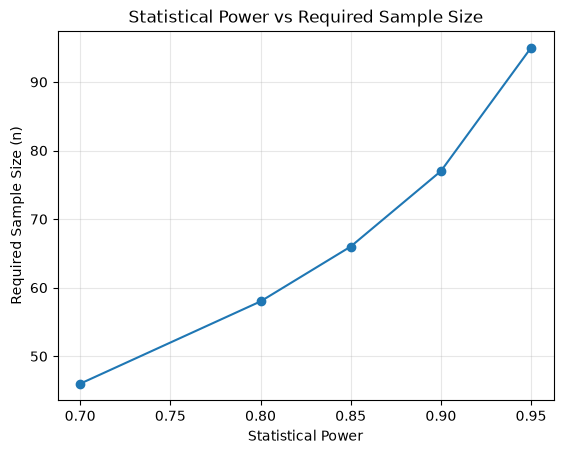

In [8]:
plt.plot(
    power_n_df["Power"],
    power_n_df["sample size"],
    marker="o"
)

plt.xlabel("Statistical Power")
plt.ylabel("Required Sample Size (n)")
plt.title("Statistical Power vs Required Sample Size")
plt.grid(alpha=0.3)
plt.show()

### the relationship between α and n

In [9]:
# Fixed assumptions
alpha = 0.05
mde = 3
planning_sd = 8
alternative = "two-sided"
stan_effect = 3 / 8

# Power scenarios
alpha_values = [0.01, 0.025, 0.05, 0.10, 0.15]

alpha_n_results = []

for alpha in alpha_values:
    n = int(np.ceil(analysis.solve_power(
        effect_size=stan_effect,
        nobs=None,
        alpha=alpha,
        power=power,
        alternative=alternative
    )))

    alpha_n_results.append({
        "Alpha":alpha,
        "sample size":n
    })

alpha_values_df = pd.DataFrame(alpha_n_results)
alpha_values_df

,Alpha,sample size
0,0.010,131
1,0.025,110
2,0.050,95
3,0.100,79
4,0.150,69


### the relationship between Variance and n

In [10]:
# Fixed assumptions
alpha = 0.05
power = 0.90
mde = 3
alternative = "two-sided"

# Standard deviation scenarios
sd_values = [4, 6, 8, 10, 12]

std_results = []

for std in sd_values:
    effect = mde / std
    n = int(np.ceil(analysis.solve_power(
        effect_size=effect,
        nobs=None,
        alpha=alpha,
        power=power,
        alternative=alternative
    )))

    std_results.append({
        "std":std,
        "n":n
    })

std_values_df = pd.DataFrame(std_results)
std_values_df

,std,n
0,4,21
1,6,44
2,8,77
3,10,119
4,12,171
